# 학생 데이터셋 추론통계

## #01. 준비단계

### 1. 라이브러리 참조

In [19]:
# 라이브러리 참조
import numpy as np
import seaborn as sb
import pandas as pd
from helpers import *
from pandas import DataFrame, read_excel

### 2. 데이터 불러오기

In [3]:
origin = pd.read_csv(r'C:\Users\reqdr\Documents\VS works\3조_student_performance_dataset_전처리완료.csv', encoding='utf-8-sig')
origin

,age,gender,city_type,study_hours_per_day,deep_work_sessions,assignment_completion_rate,attendance_percentage,social_media_hours,doomscrolling_before_sleep,notification_distractions,...,family_support,financial_stress,learning_style,career_goal,productivity_after_midnight,revision_efficiency,burnout_risk,consistency_score,final_exam_score,performance_category
0,21,Female,Semi-Urban,3.2,7,100,70,3.8,0,107,...,10,6,Audio,Engineering,9,1,10,3,32,Low
1,19,Female,Semi-Urban,3.9,2,46,70,2.6,1,93,...,2,6,Practical,Business,6,10,4,6,59,Medium
2,16,Female,Urban,4.3,7,54,57,4.3,1,82,...,1,9,Visual,Engineering,7,9,8,1,34,Low
3,19,Male,Semi-Urban,5.3,1,78,90,1.7,0,27,...,5,10,Reading,Medical,7,7,9,10,60,Medium
4,17,Female,Urban,4.1,3,100,81,2.6,0,8,...,5,6,Visual,Medical,4,10,7,9,77,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,22,Female,Rural,2.4,0,40,83,1.0,0,71,...,10,2,Practical,Arts,9,10,7,9,45,Low
2996,19,Female,Urban,5.2,7,94,100,1.4,0,114,...,1,10,Visual,Medical,5,3,7,9,100,High
2997,23,Female,Rural,5.9,2,41,86,5.4,1,88,...,7,10,Practical,Engineering,6,8,10,10,50,Medium
2998,17,Male,Urban,3.9,1,92,96,2.8,1,94,...,3,10,Practical,Medical,4,7,1,4,76,High


### 3. 타입 점검 및 변환

In [ ]:
origin['gender'] = origin['gender'].astype('category')
origin['city_type'] = origin['city_type'].astype('category')
origin['doomscrolling_before_sleep'] = origin['doomscrolling_before_sleep'].astype('category')
origin['mental_state'] = origin['mental_state'].astype('category')
origin['learning_style'] = origin['learning_style'].astype('category')
origin['career_goal'] = origin['career_goal'].astype('category')
origin['performance_category'] = origin['performance_category'].astype('category')
df = origin.copy()
df = df.dropna().reset_index(drop=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   age                          3000 non-null   int64   
 1   gender                       3000 non-null   category
 2   city_type                    3000 non-null   category
 3   study_hours_per_day          3000 non-null   float64 
 4   deep_work_sessions           3000 non-null   int64   
 5   assignment_completion_rate   3000 non-null   int64   
 6   attendance_percentage        3000 non-null   int64   
 7   social_media_hours           2940 non-null   float64 
 8   doomscrolling_before_sleep   3000 non-null   category
 9   notification_distractions    3000 non-null   int64   
 10  ai_tool_usage_hours          3000 non-null   float64 
 11  gaming_hours                 3000 non-null   float64 
 12  stress_level                 3000 non-null   int64   
 13  motivation_lev

### 4. 변수 유형 분류

In [5]:
# 종속변수
target = "final_exam_score"

# 명목형 변수 이름
nominal_cols = my_qtcheck.get_categorical_column_names(df)

# 연속형(종속변수 포함)
continuous_cols = my_qtcheck.get_number_column_names(df)

# 연속형 독립변수
feature_continuous = [c for c in continuous_cols if c != target]

print("목표변수 :", target)
print("명목형 :", nominal_cols)
print("연속형 :", continuous_cols)

목표변수 : final_exam_score
명목형 : ['gender', 'city_type', 'doomscrolling_before_sleep', 'mental_state', 'learning_style', 'career_goal', 'performance_category']
연속형 : ['age', 'study_hours_per_day', 'deep_work_sessions', 'assignment_completion_rate', 'attendance_percentage', 'social_media_hours', 'notification_distractions', 'ai_tool_usage_hours', 'gaming_hours', 'stress_level', 'motivation_level', 'focus_score', 'procrastination_index', 'sleep_hours', 'caffeine_intake', 'physical_activity_hours', 'internet_quality', 'family_support', 'financial_stress', 'productivity_after_midnight', 'revision_efficiency', 'burnout_risk', 'consistency_score', 'final_exam_score']


## #02. 데이터 시각화

### 2. 명목형

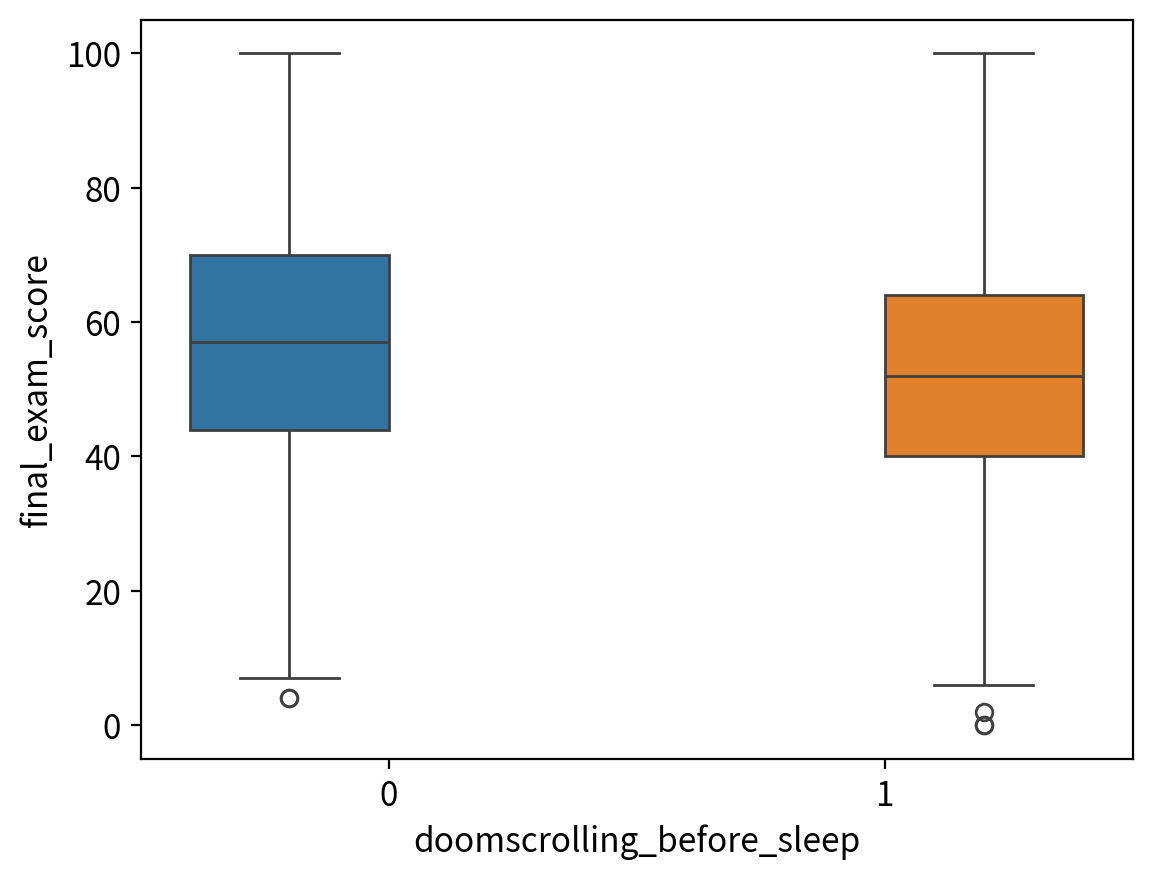

In [31]:

ax = sb.boxplot(
    data=df,
    x="doomscrolling_before_sleep",
    y="final_exam_score",
    hue="doomscrolling_before_sleep",
    legend=False
    )



# 그래프 표시
plt.show()

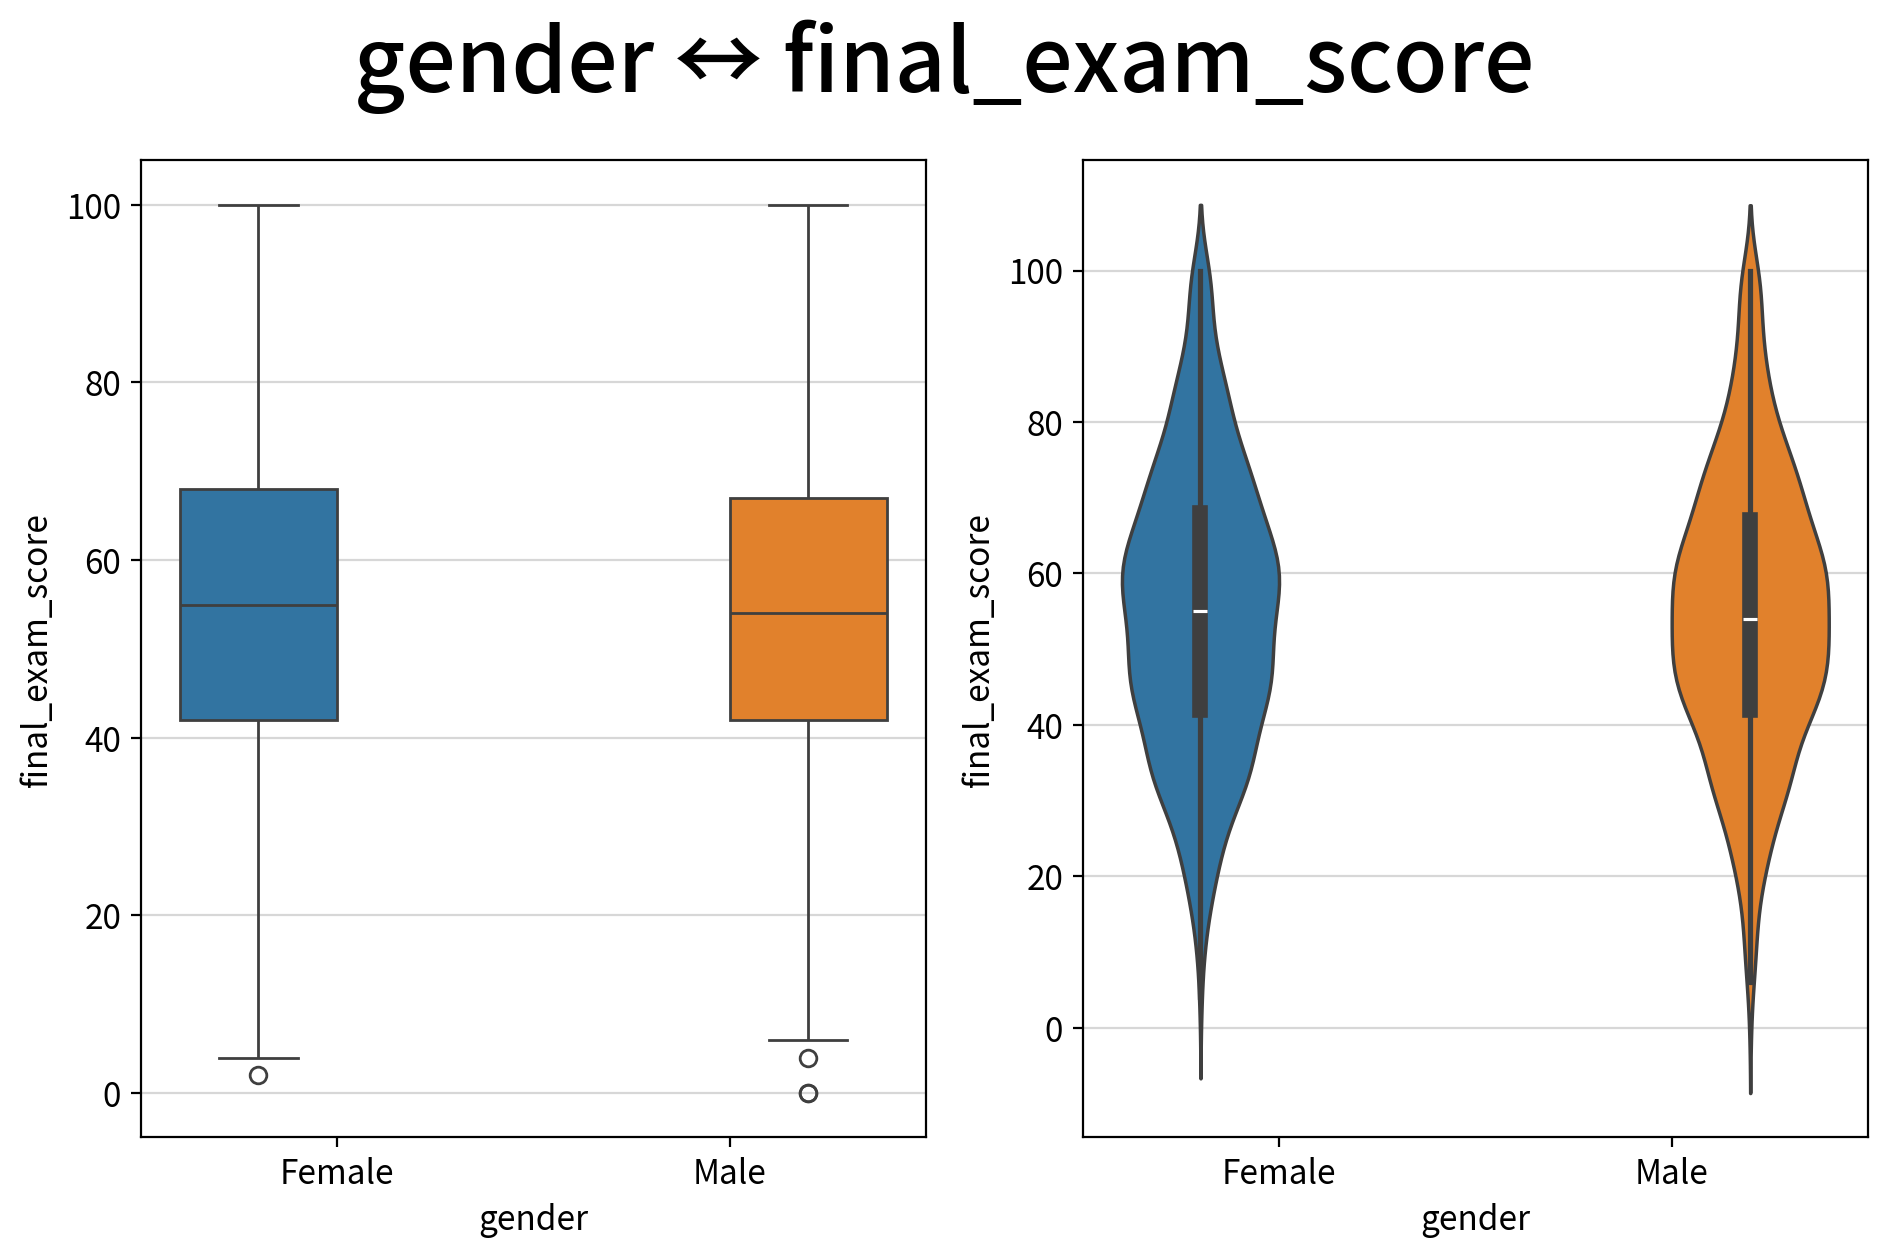

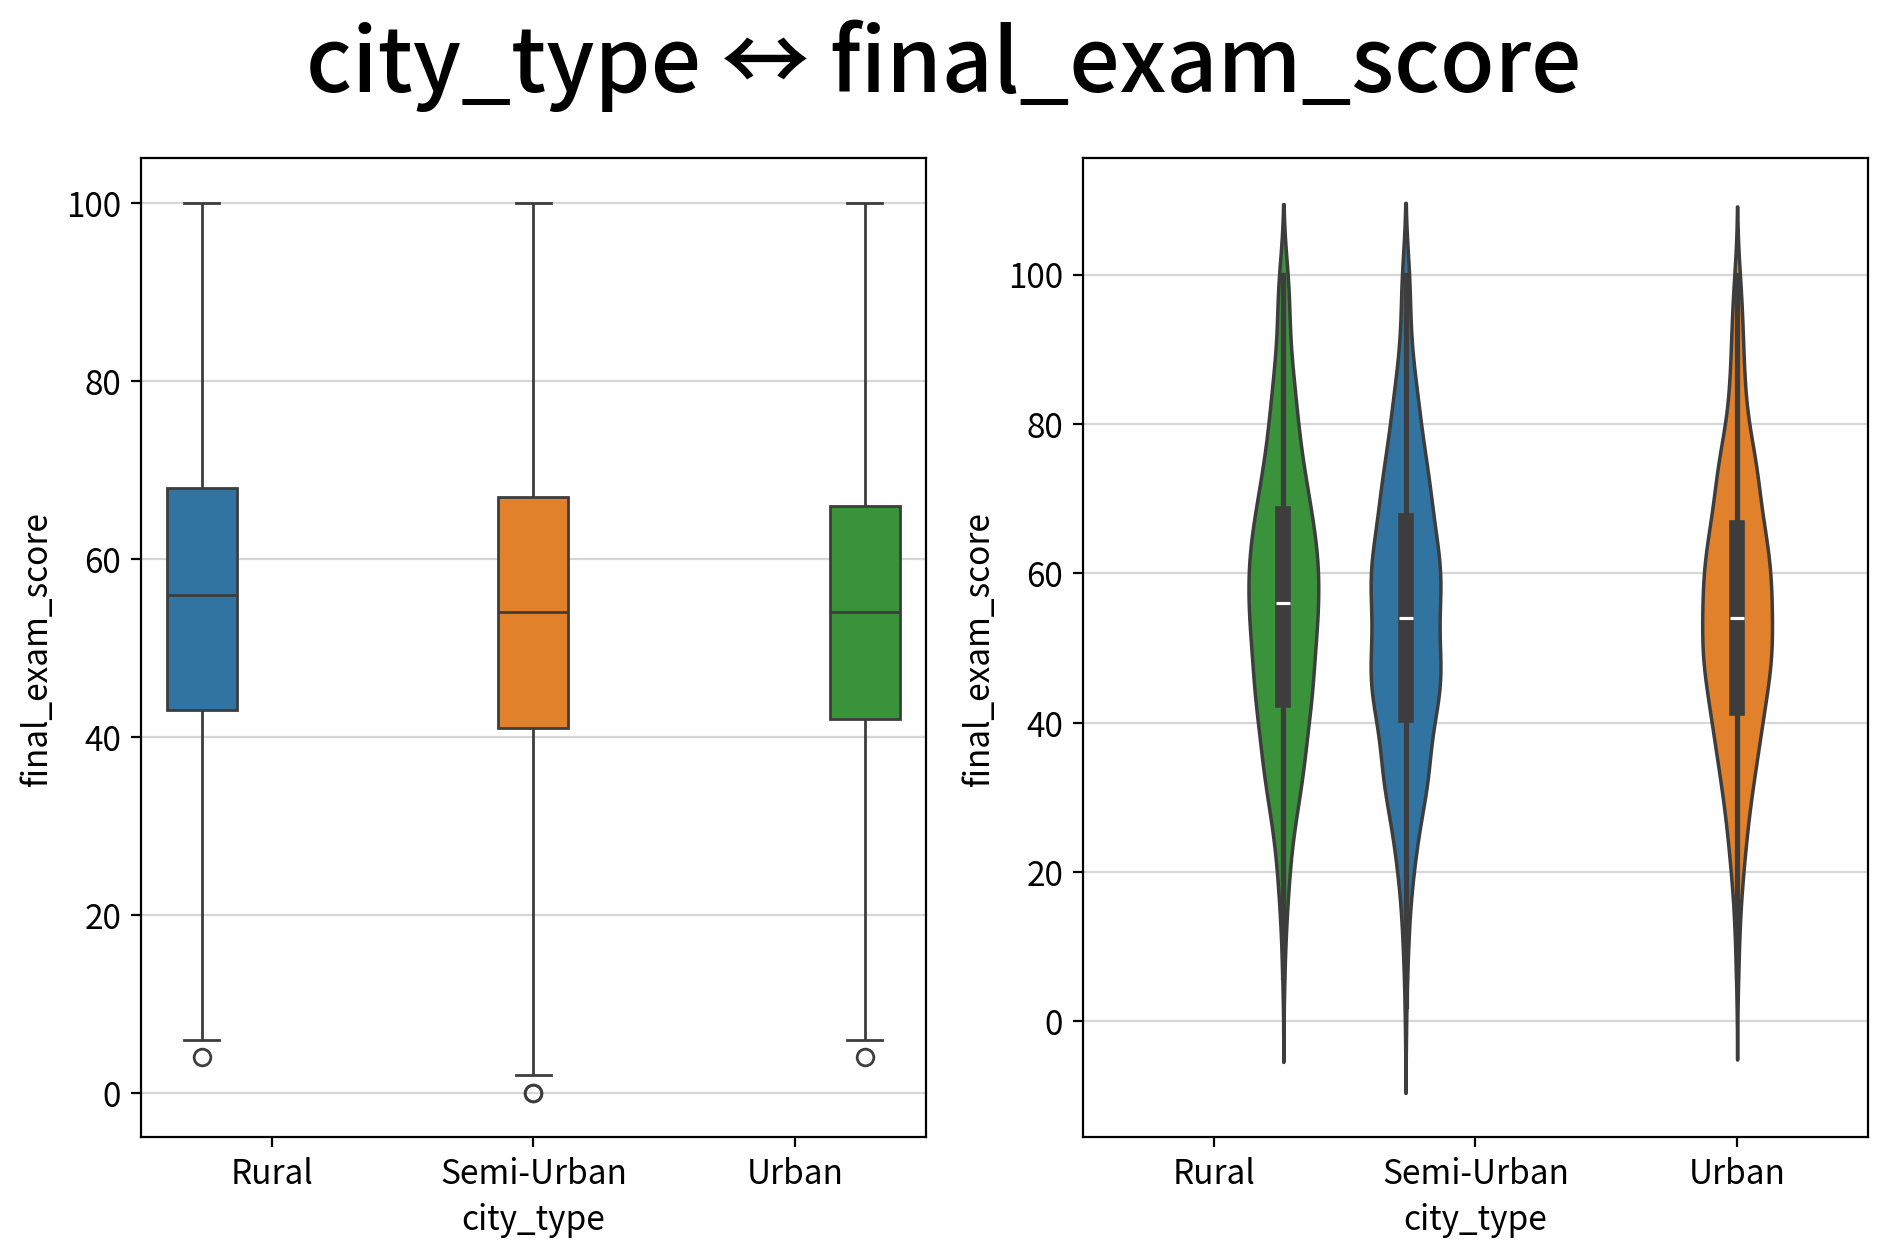

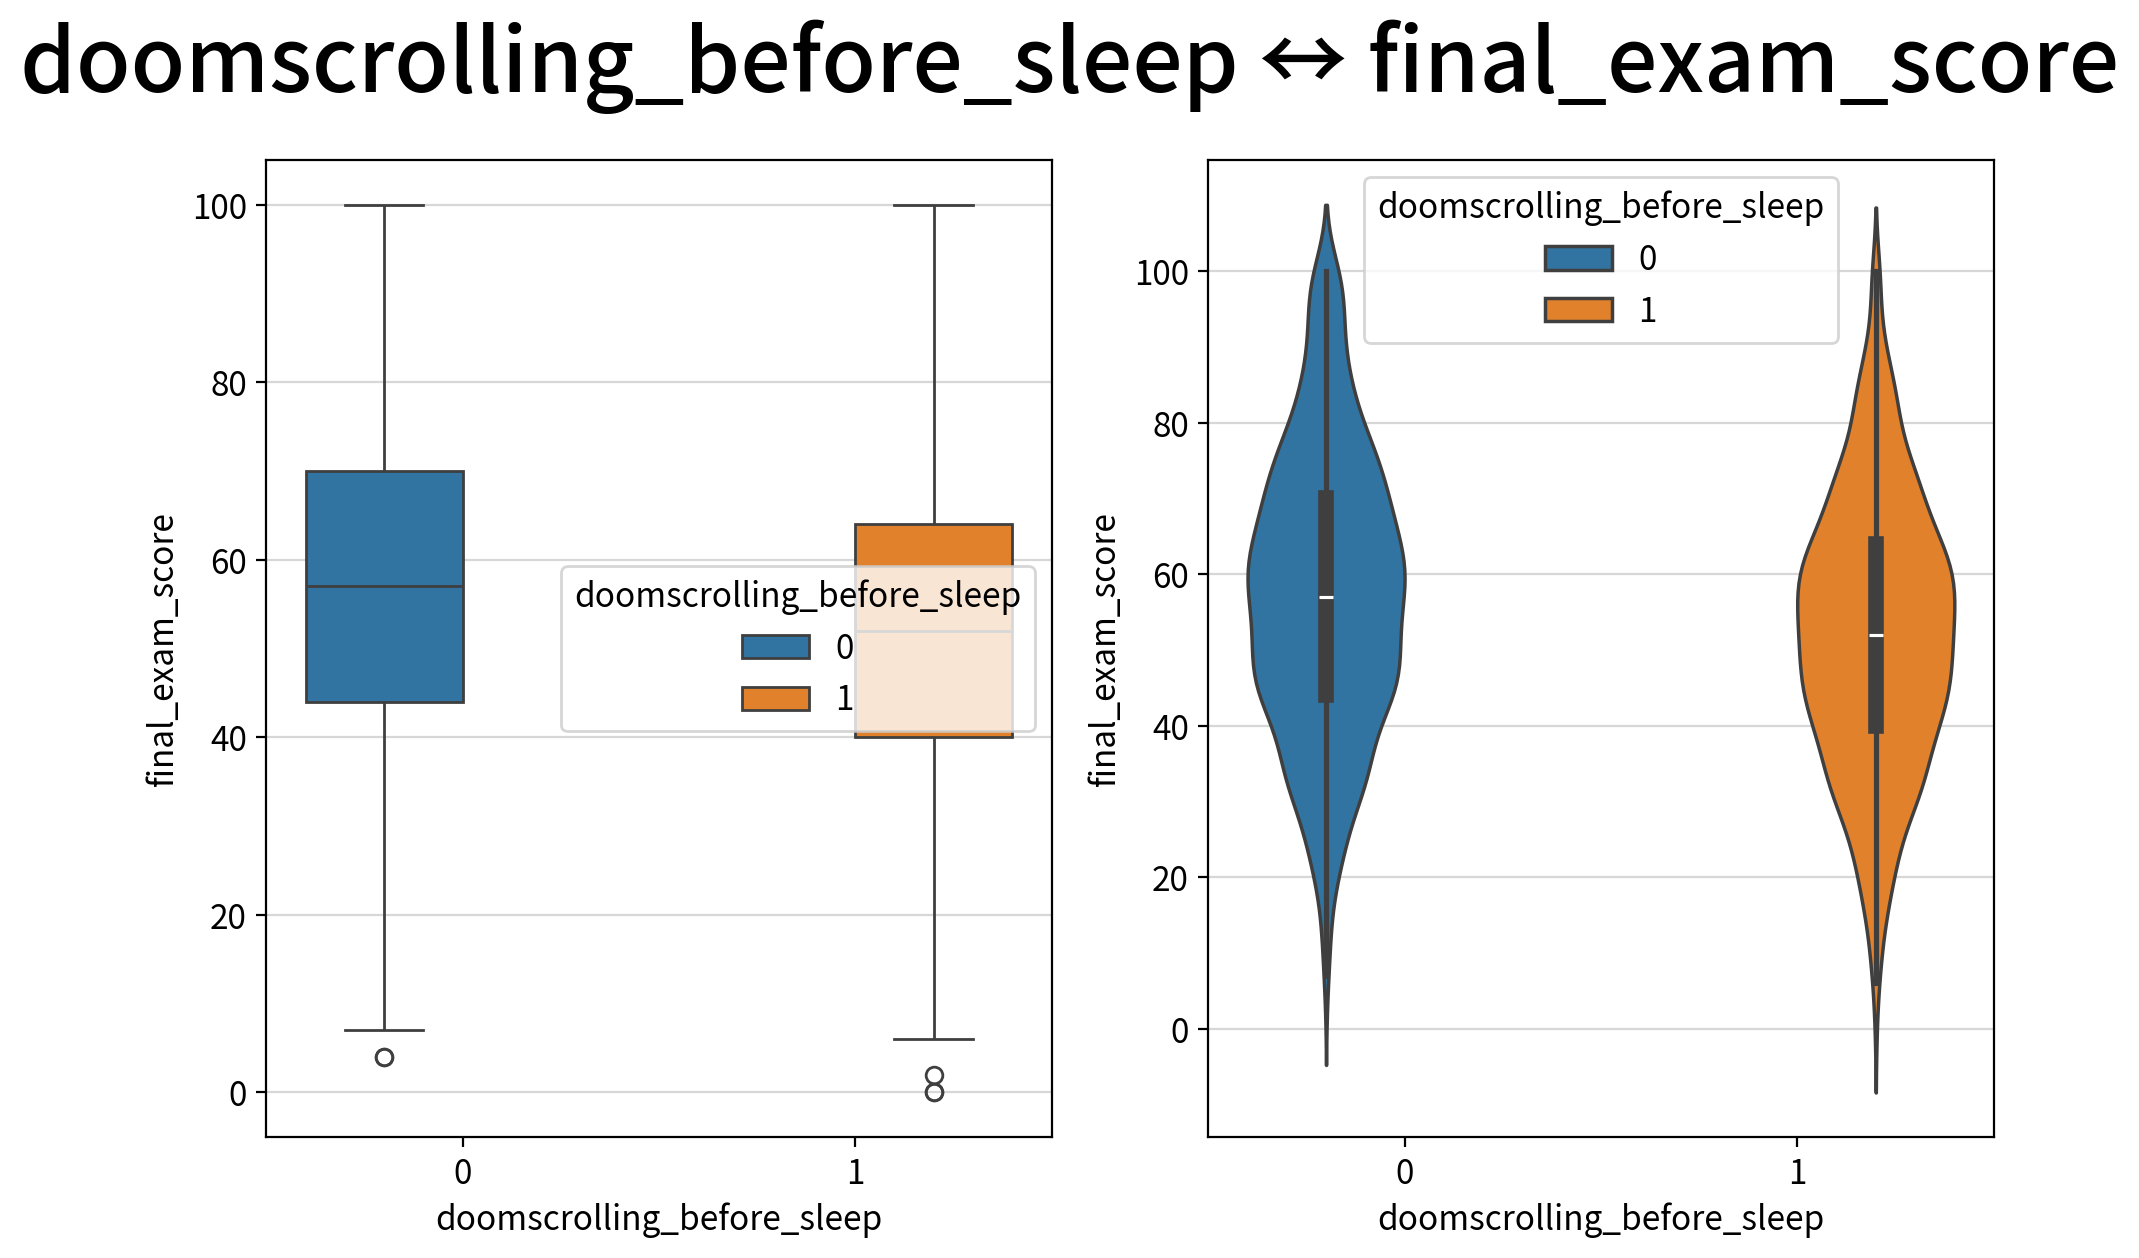

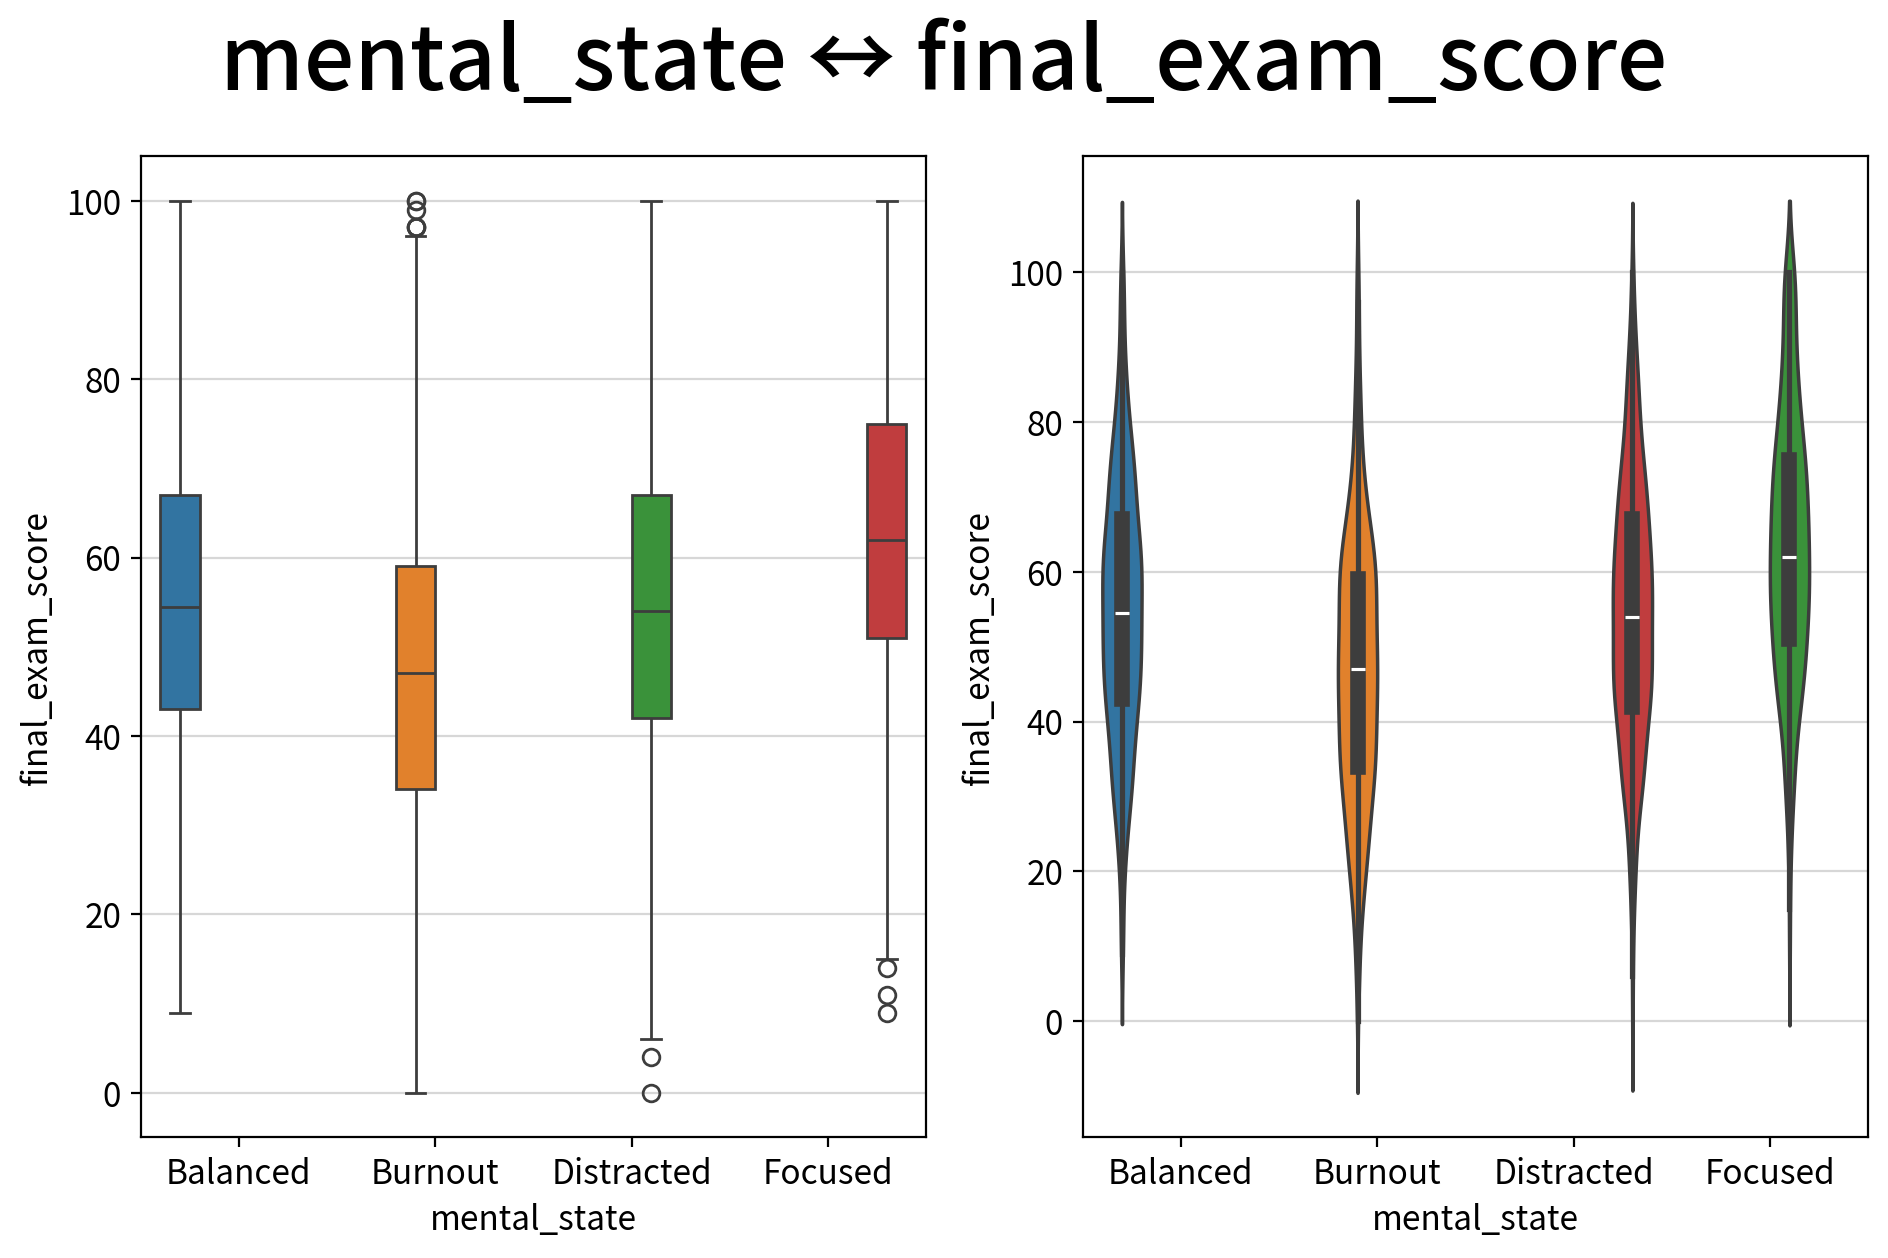

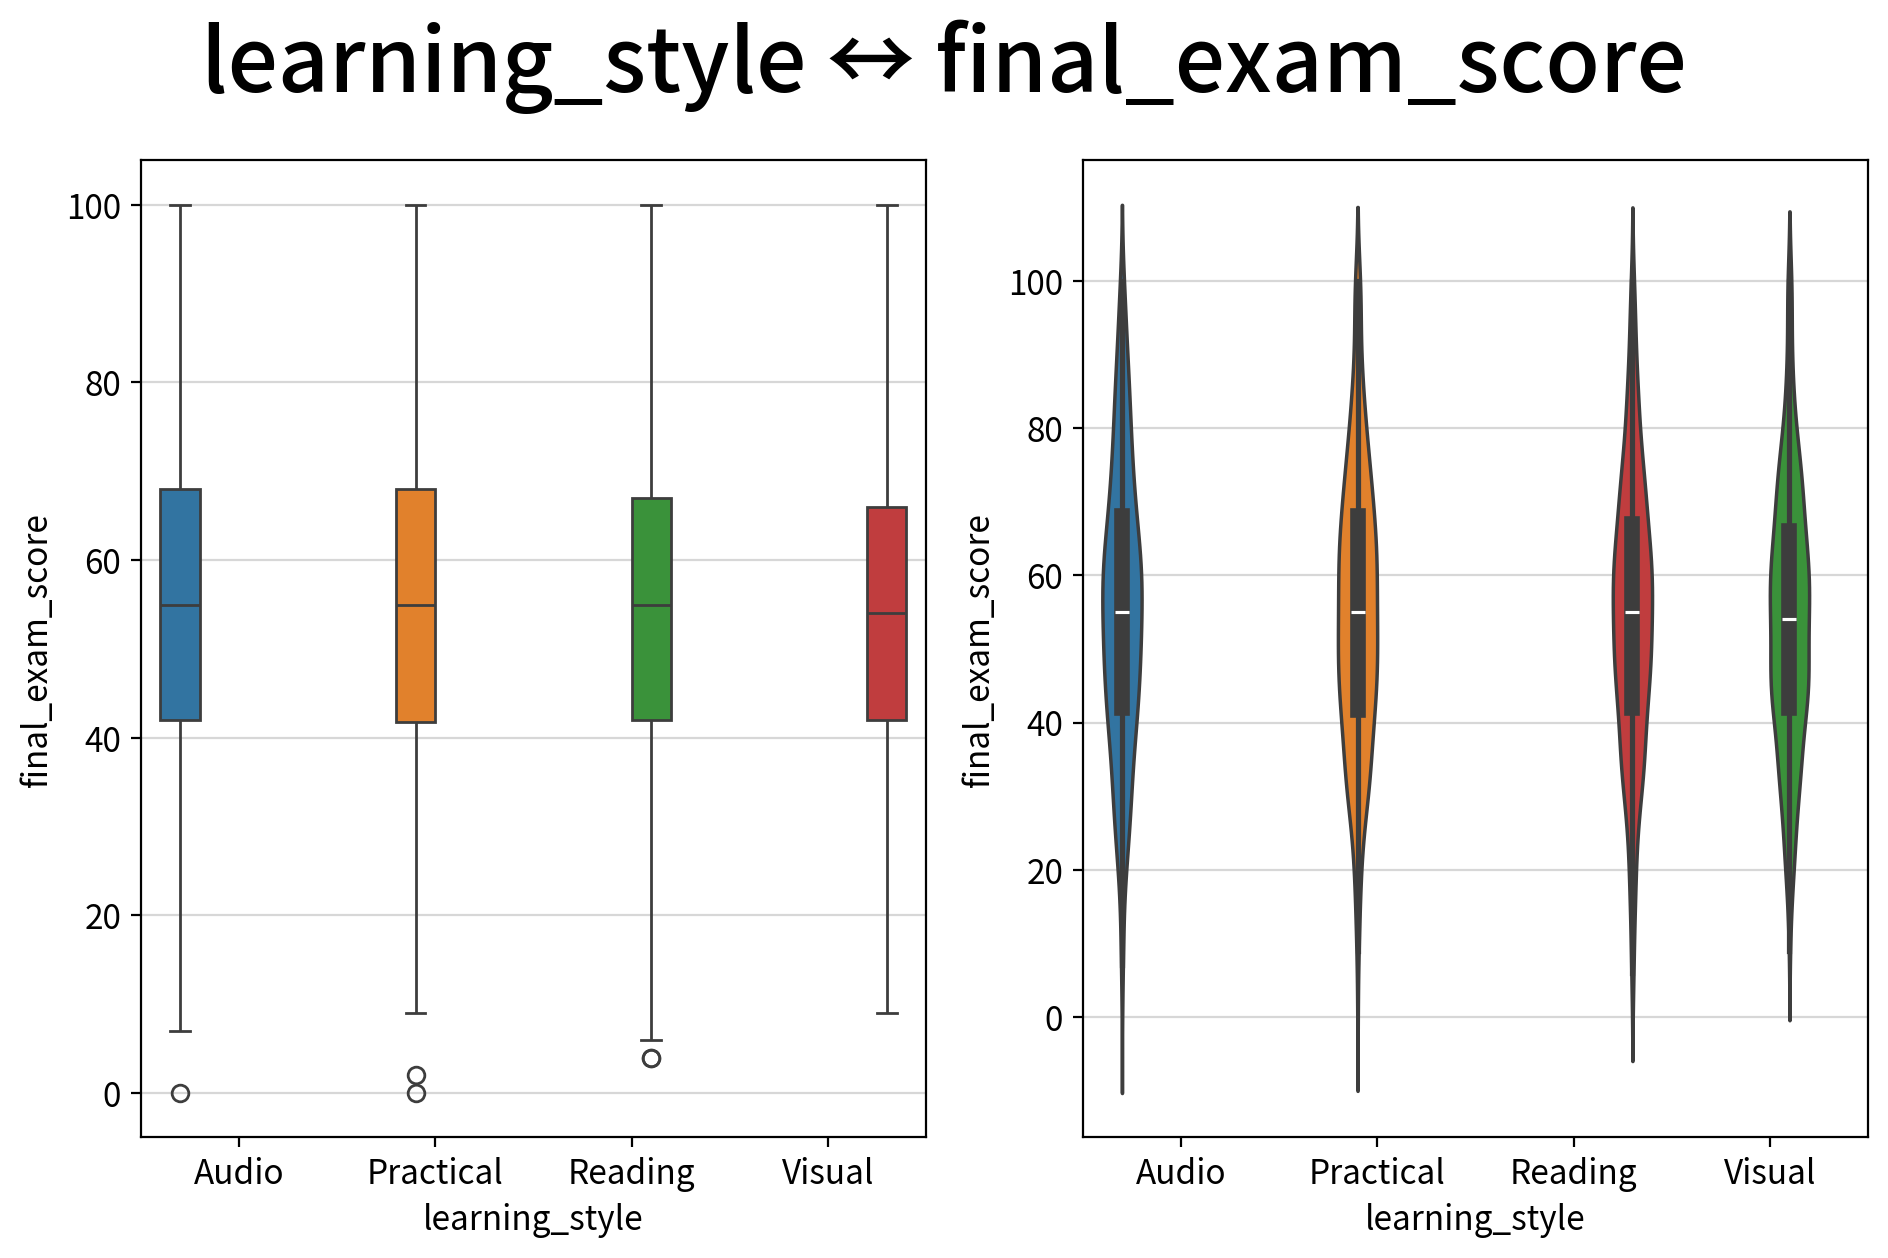

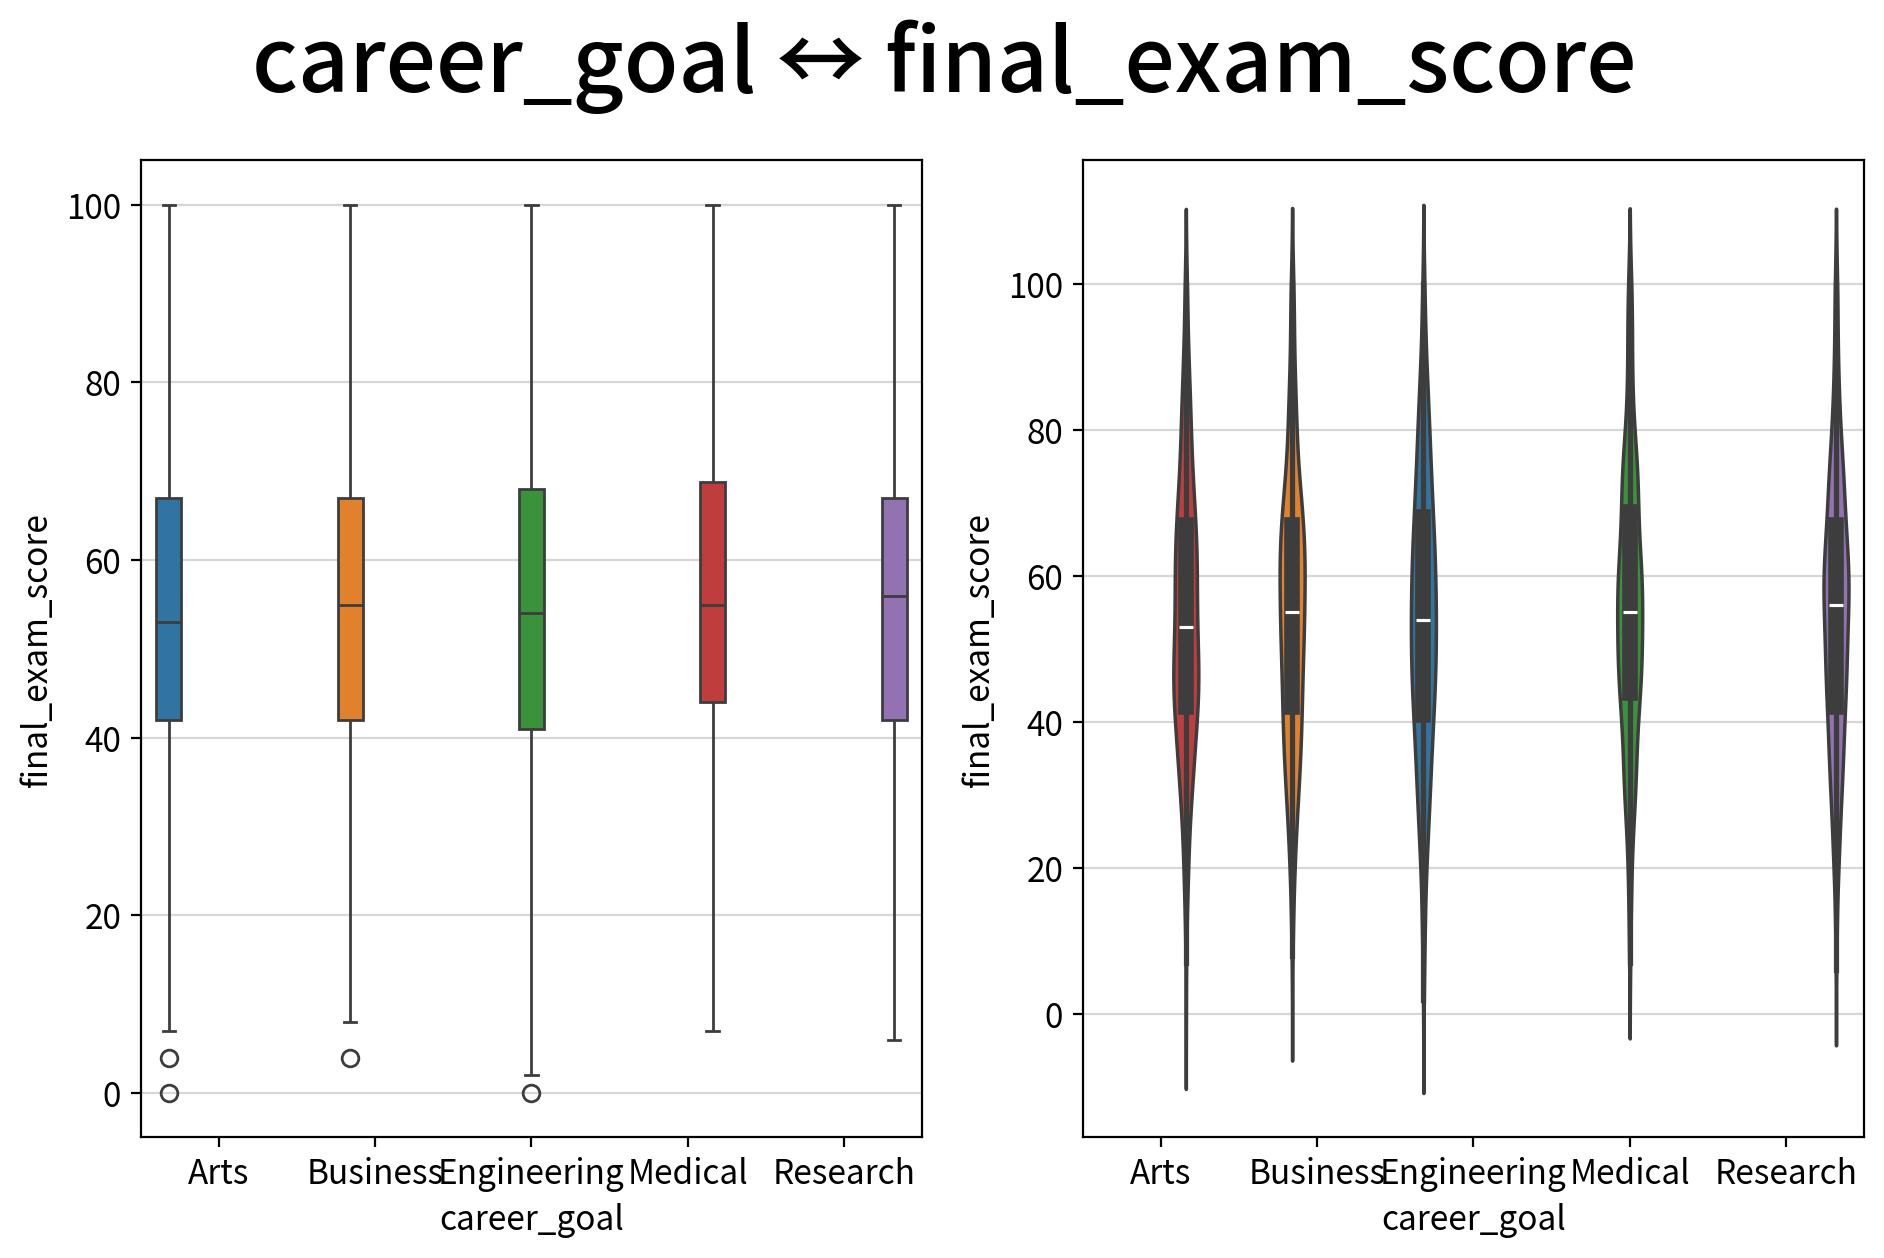

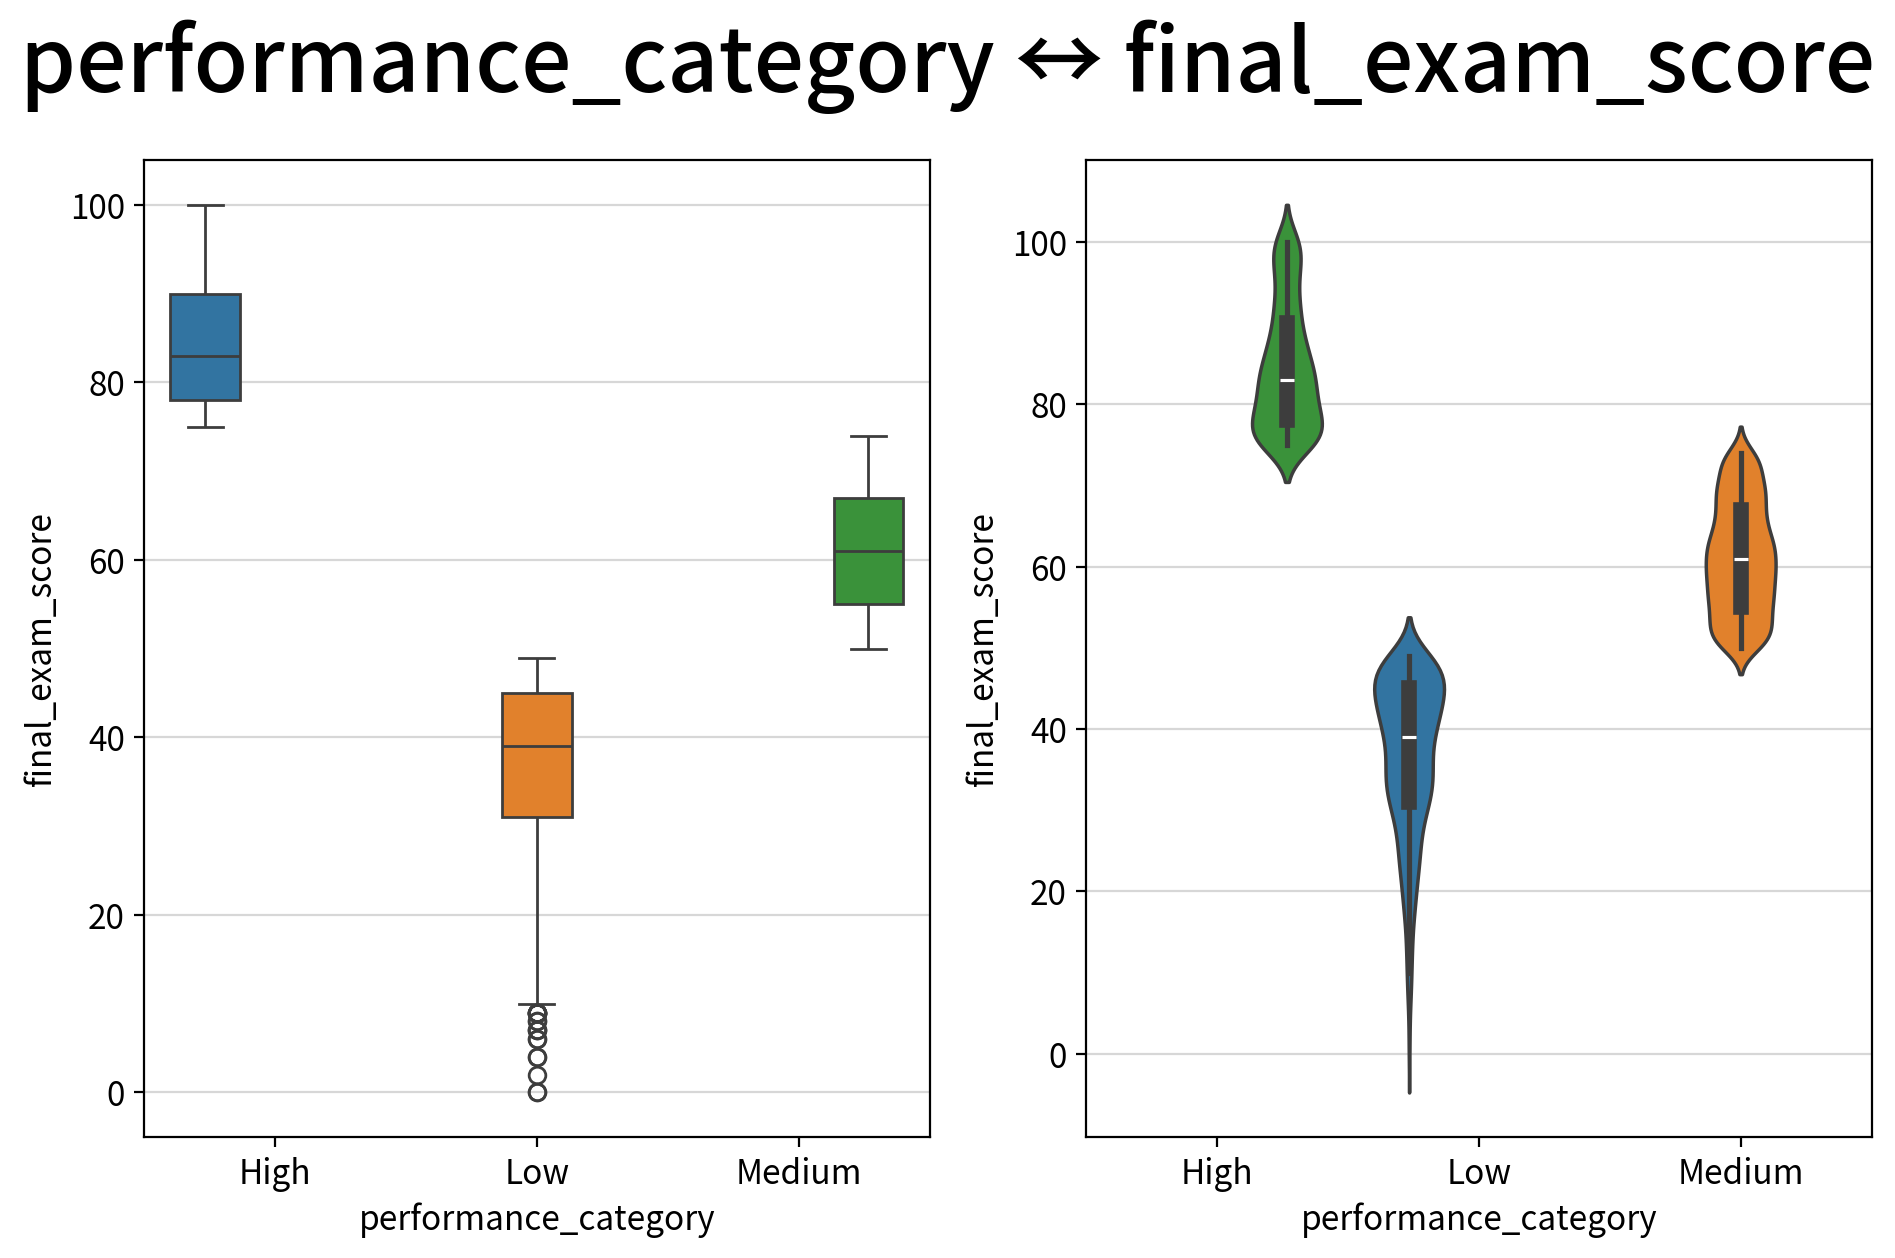

In [30]:
for n in nominal_cols:
    # 명목(2집단) ↔ 연속 : 박스플롯 + 바이올린으로 그룹간 분포 비교
    fig, ax = my_plot.init(rows=1, cols=2, title=f"{n} ↔ {target}", 
                           width=960, height=640)
    my_plot.boxplot(data=df, x=n, y=target, hue=n, ax=ax[0])
    my_plot.violinplot(data=df, x=n, y=target, hue=n, ax=ax[1])
    my_plot.show()

## #03. 상관분석

### 1. 연속형 종속변수 ↔ 연속형 독립변수

In [7]:
for f in feature_continuous:
    result = my_stats.correlation(df, x=f, y=target, plot=False)
    print(f"\n독립변수 : {f}")
    display(result)


독립변수 : age


,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
age,final_exam_score,Spearman,0.0016,0.9301,Weak,False,False,False,True,False,False



독립변수 : study_hours_per_day


,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
study_hours_per_day,final_exam_score,Spearman,0.3042,0.0,Moderate,True,False,False,True,False,False



독립변수 : deep_work_sessions


,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
deep_work_sessions,final_exam_score,Spearman,0.0788,0.0,Weak,True,False,False,False,False,False


... (36 outputs left out)


독립변수 : burnout_risk


,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
burnout_risk,final_exam_score,Spearman,-0.2379,0.0,Weak,True,False,False,True,False,False



독립변수 : consistency_score


,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
consistency_score,final_exam_score,Spearman,0.3274,0.0,Moderate,True,False,False,True,False,False


### 2. 연속형 독립변수간의 상관분석

In [8]:
my_stats.multi_correlation(df, columns=feature_continuous, plot=False)

method    coef  \
x                           y                                              
age                         study_hours_per_day         Spearman -0.0053   
                            deep_work_sessions          Spearman  0.0166   
                            assignment_completion_rate  Spearman -0.0266   
                            attendance_percentage       Spearman  0.0021   
                            social_media_hours          Spearman -0.0096   
...                                                          ...     ...   
productivity_after_midnight burnout_risk                Spearman -0.0120   
                            consistency_score           Spearman  0.0125   
revision_efficiency         burnout_risk                Spearman  0.0147   
                            consistency_score           Spearman  0.0144   
burnout_risk                consistency_score           Spearman  0.0046   

                                                        p-value strength  \
x                           y                                              
age                         study_hours_per_day          0.7717     Weak   
                            deep_work_sessions           0.3626     Weak   
                            assignment_completion_rate   0.1452     Weak   
                            attendance_percentage        0.9085     Weak   
                            social_media_hours           0.6044     Weak   
...                                                         ...      ...   
productivity_after_midnight burnout_risk                 0.5126     Weak   
                            consistency_score            0.4922     Weak   
revision_efficiency         burnout_risk                 0.4222     Weak   
                            consistency_score            0.4316     Weak   
burnout_risk                consistency_score            0.8030     Weak   

                                                        significant  \
x                           y                                         
age                         study_hours_per_day               False   
                            deep_work_sessions                 True   
                            assignment_completion_rate         True   
                            attendance_percentage             False   
                            social_media_hours                False   
...                                                             ...   
productivity_after_midnight burnout_risk                      False   
                            consistency_score                  True   
revision_efficiency         burnout_risk                       True   
                            consistency_score                  True   
burnout_risk                consistency_score                 False   

                                                        normality_x  \
x                           y                                         
age                         study_hours_per_day               False   
                            deep_work_sessions                False   
                            assignment_completion_rate        False   
                            attendance_percentage             False   
                            social_media_hours                False   
...                                                             ...   
productivity_after_midnight burnout_risk                      False   
                            consistency_score                 False   
revision_efficiency         burnout_risk                      False   
                            consistency_score                 False   
burnout_risk                consistency_score                 False   

                                                        normality_y  \
x                           y                                         
age                         study_hours_per_day               False   
                   

,age,study_hours_per_day,deep_work_sessions,assignment_completion_rate,attendance_percentage,social_media_hours,notification_distractions,ai_tool_usage_hours,gaming_hours,stress_level,motivation_level,focus_score,procrastination_index,sleep_hours,caffeine_intake,physical_activity_hours,internet_quality,family_support,financial_stress,productivity_after_midnight,revision_efficiency,burnout_risk,consistency_score
age,1.000,-0.005,0.017,-0.027,0.002,-0.010,-0.019,-0.038,0.018,0.012,0.013,0.003,-0.002,-0.021,-0.004,-0.002,0.013,-0.009,0.034,0.017,-0.013,-0.007,0.017
study_hours_per_day,-0.005,1.000,-0.020,-0.011,-0.000,-0.004,-0.011,-0.003,0.014,-0.012,-0.008,-0.002,0.004,-0.019,0.010,-0.009,0.002,-0.010,0.011,-0.006,-0.002,0.007,0.023
deep_work_sessions,0.017,-0.020,1.000,-0.018,-0.035,-0.030,-0.005,0.032,-0.007,0.004,0.009,-0.005,0.008,0.002,0.008,-0.003,-0.013,0.007,-0.012,0.032,-0.014,-0.023,-0.000
assignment_completion_rate,-0.027,-0.011,-0.018,1.000,-0.005,0.005,0.020,0.003,-0.003,-0.004,-0.003,-0.019,-0.003,-0.010,-0.012,0.003,0.014,-0.008,0.015,0.025,-0.004,0.007,-0.030
attendance_percentage,0.002,-0.000,-0.035,-0.005,1.000,-0.009,0.013,0.019,0.004,-0.020,0.001,0.004,-0.023,0.016,-0.016,0.013,-0.006,0.004,0.018,0.002,0.011,-0.005,-0.010
social_media_hours,-0.010,-0.004,-0.030,0.005,-0.009,1.000,0.004,-0.010,0.011,0.006,-0.011,-0.007,-0.020,0.015,-0.043,-0.016,-0.013,0.036,-0.023,-0.007,0.010,-0.018,-0.043
notification_distractions,-0.019,-0.011,-0.005,0.020,0.013,0.004,1.000,0.006,-0.007,-0.003,-0.027,-0.007,0.009,-0.019,-0.015,-0.005,-0.024,0.031,0.014,-0.001,0.011,-0.009,-0.009
ai_tool_usage_hours,-0.038,-0.003,0.032,0.003,0.019,-0.010,0.006,1.000,-0.015,-0.003,-0.005,0.016,-0.011,-0.015,0.005,0.011,0.003,-0.005,-0.021,-0.040,-0.007,-0.011,-0.018
gaming_hours,0.018,0.014,-0.007,-0.003,0.004,0.011,-0.007,-0.015,1.000,0.007,0.016,-0.038,-0.027,-0.004,-0.008,0.020,-0.002,-0.036,-0.004,0.003,0.003,0.010,-0.015
stress_level,0.012,-0.012,0.004,-0.004,-0.020,0.006,-0.003,-0.003,0.007,1.000,0.011,0.001,0.022,0.032,0.000,-0.005,0.006,0.021,0.015,-0.007,0.007,0.014,0.032


## #03. T검정

### 1. 이진 명목형 변수 ↔ 연속형

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

여성 vs. 남성: Mann-Whitney-Wilcoxon test two-sided, P_val:4.587e-01 U_stat=1.142e+06


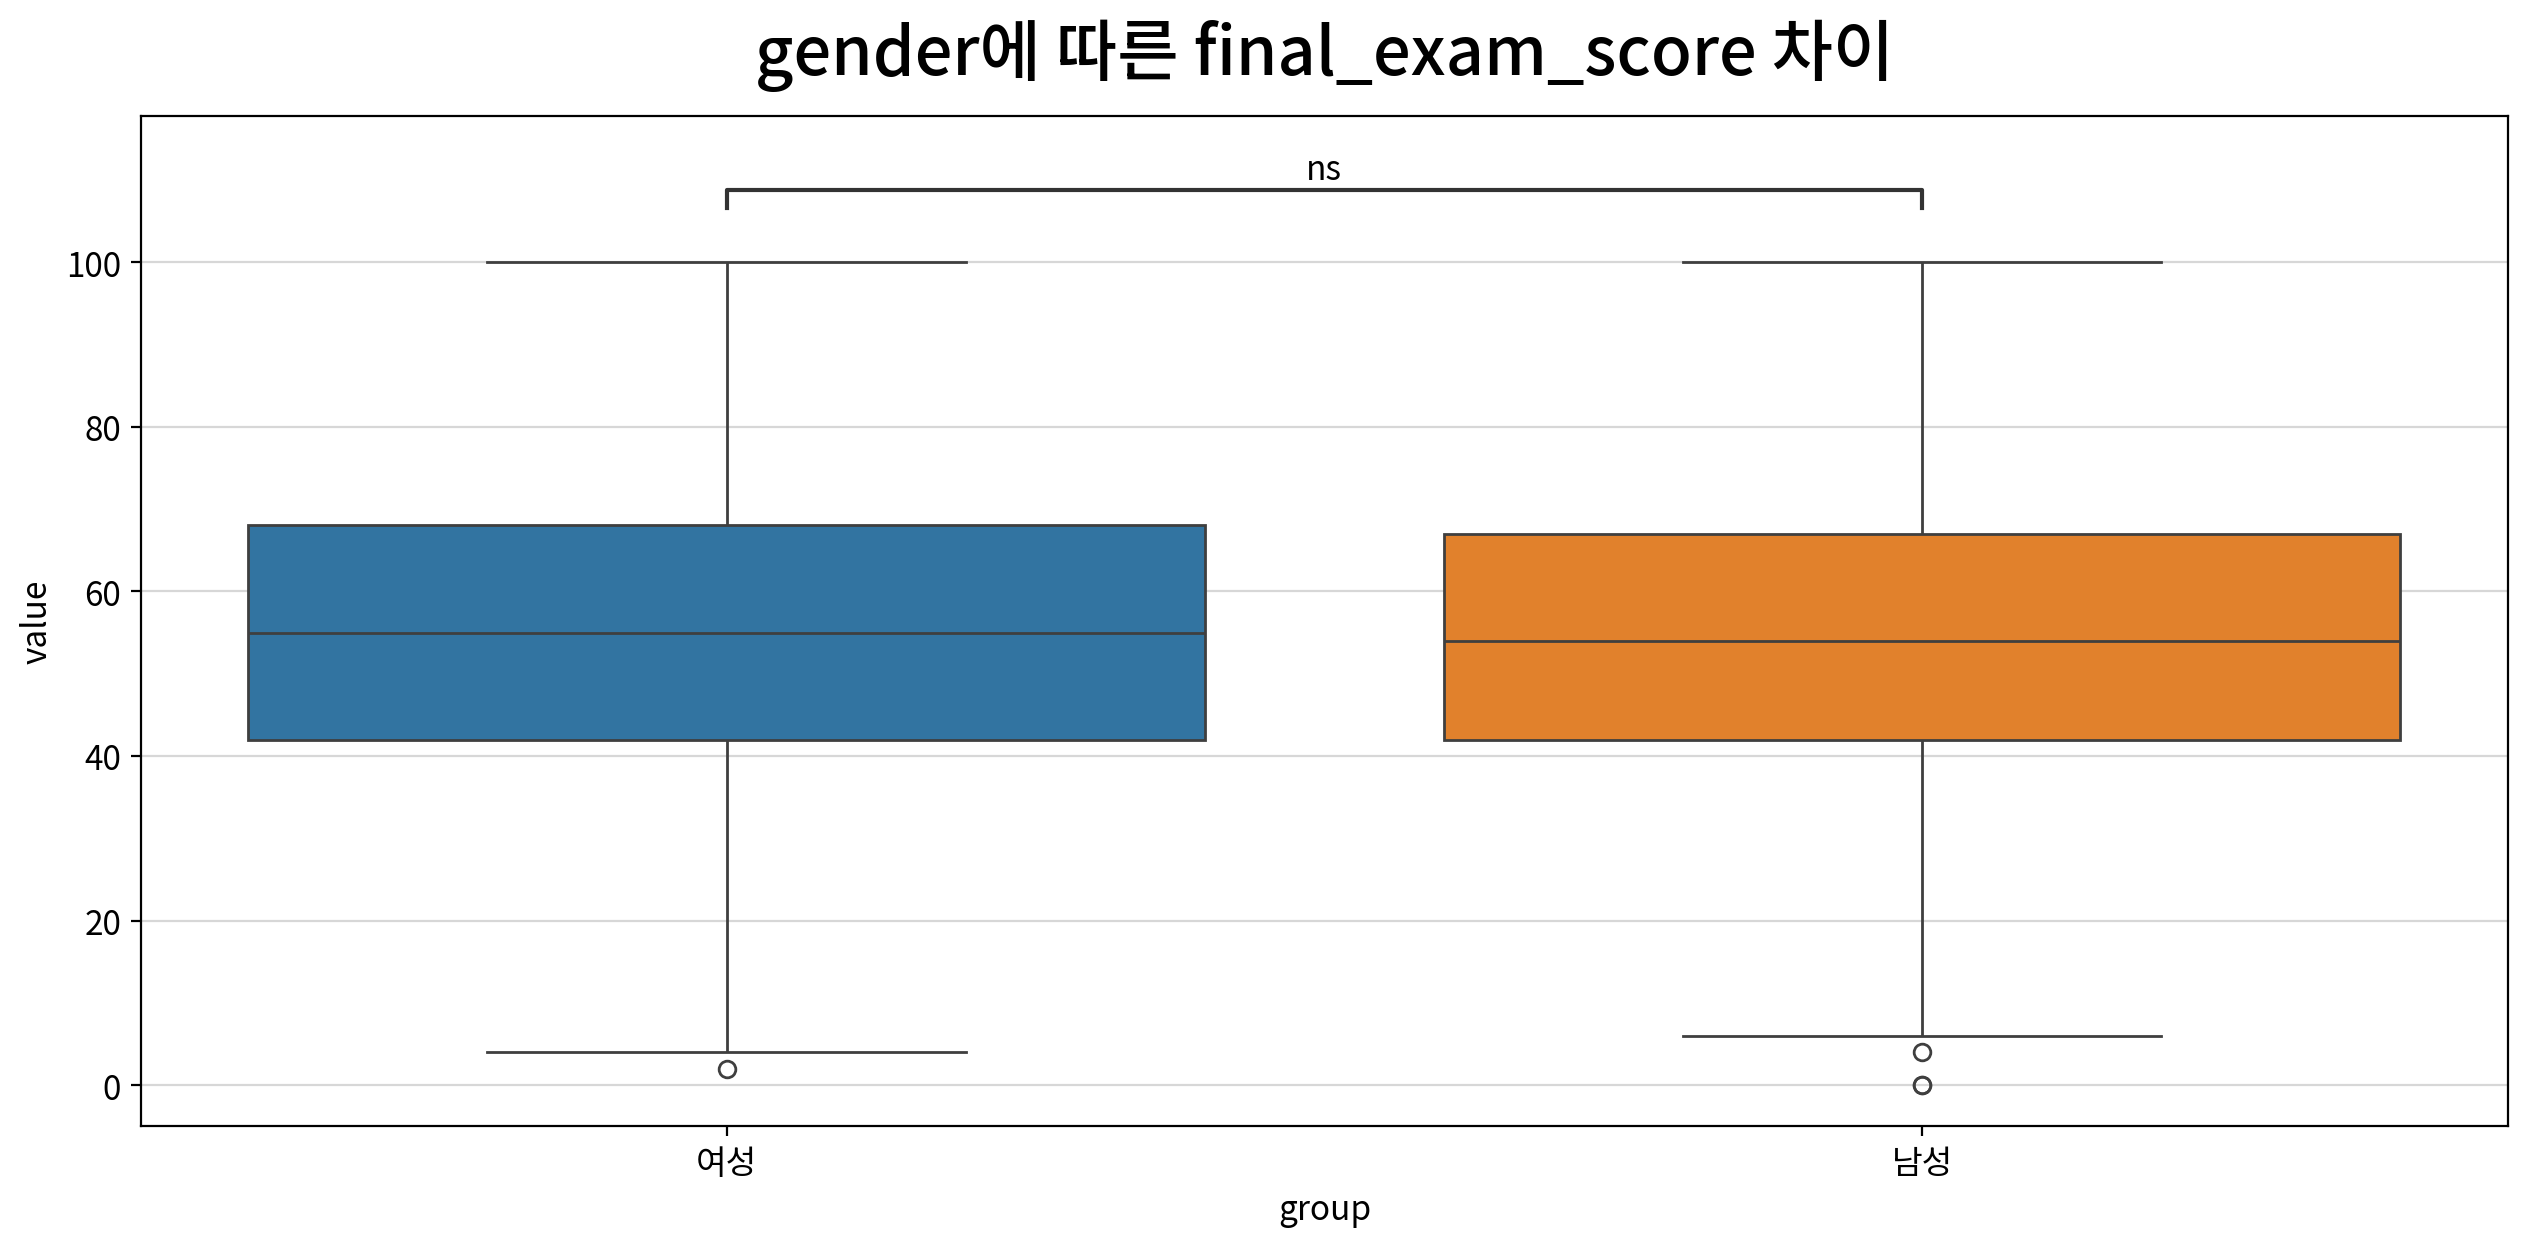

statistic  p-value  significant   result
test                alternative                                          
Mann-Whitney U test two-sided    1142181.0   0.4587        False  여성 = 남성
                    less         1142181.0   0.7707        False  여성 ≥ 남성
                    greater      1142181.0   0.2293        False  여성 ≤ 남성

In [9]:
# gender
chas_medv = DataFrame({
    "여성": df.loc[df["gender"] == 'Female', target].reset_index(drop=True),
    "남성" : df.loc[df["gender"] == 'Male', target].reset_index(drop=True),
})

my_stats.test_independent(chas_medv, "여성", "남성", title="gender에 따른 final_exam_score 차이")

c:\Users\reqdr\Documents\VS works\helpers\my_stats.py:84: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  s, p = normaltest(data[c])
c:\Users\reqdr\Documents\VS works\helpers\my_stats.py:107: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  s, p = levene(*samples, center=center)
c:\Users\reqdr\Documents\VS works\helpers\my_stats.py:348: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = mannwhitneyu(a, b, alternative=alt)


ValueError: Missing value(s) ['아니오', '예'] for group (specified in `pairs`) in data.

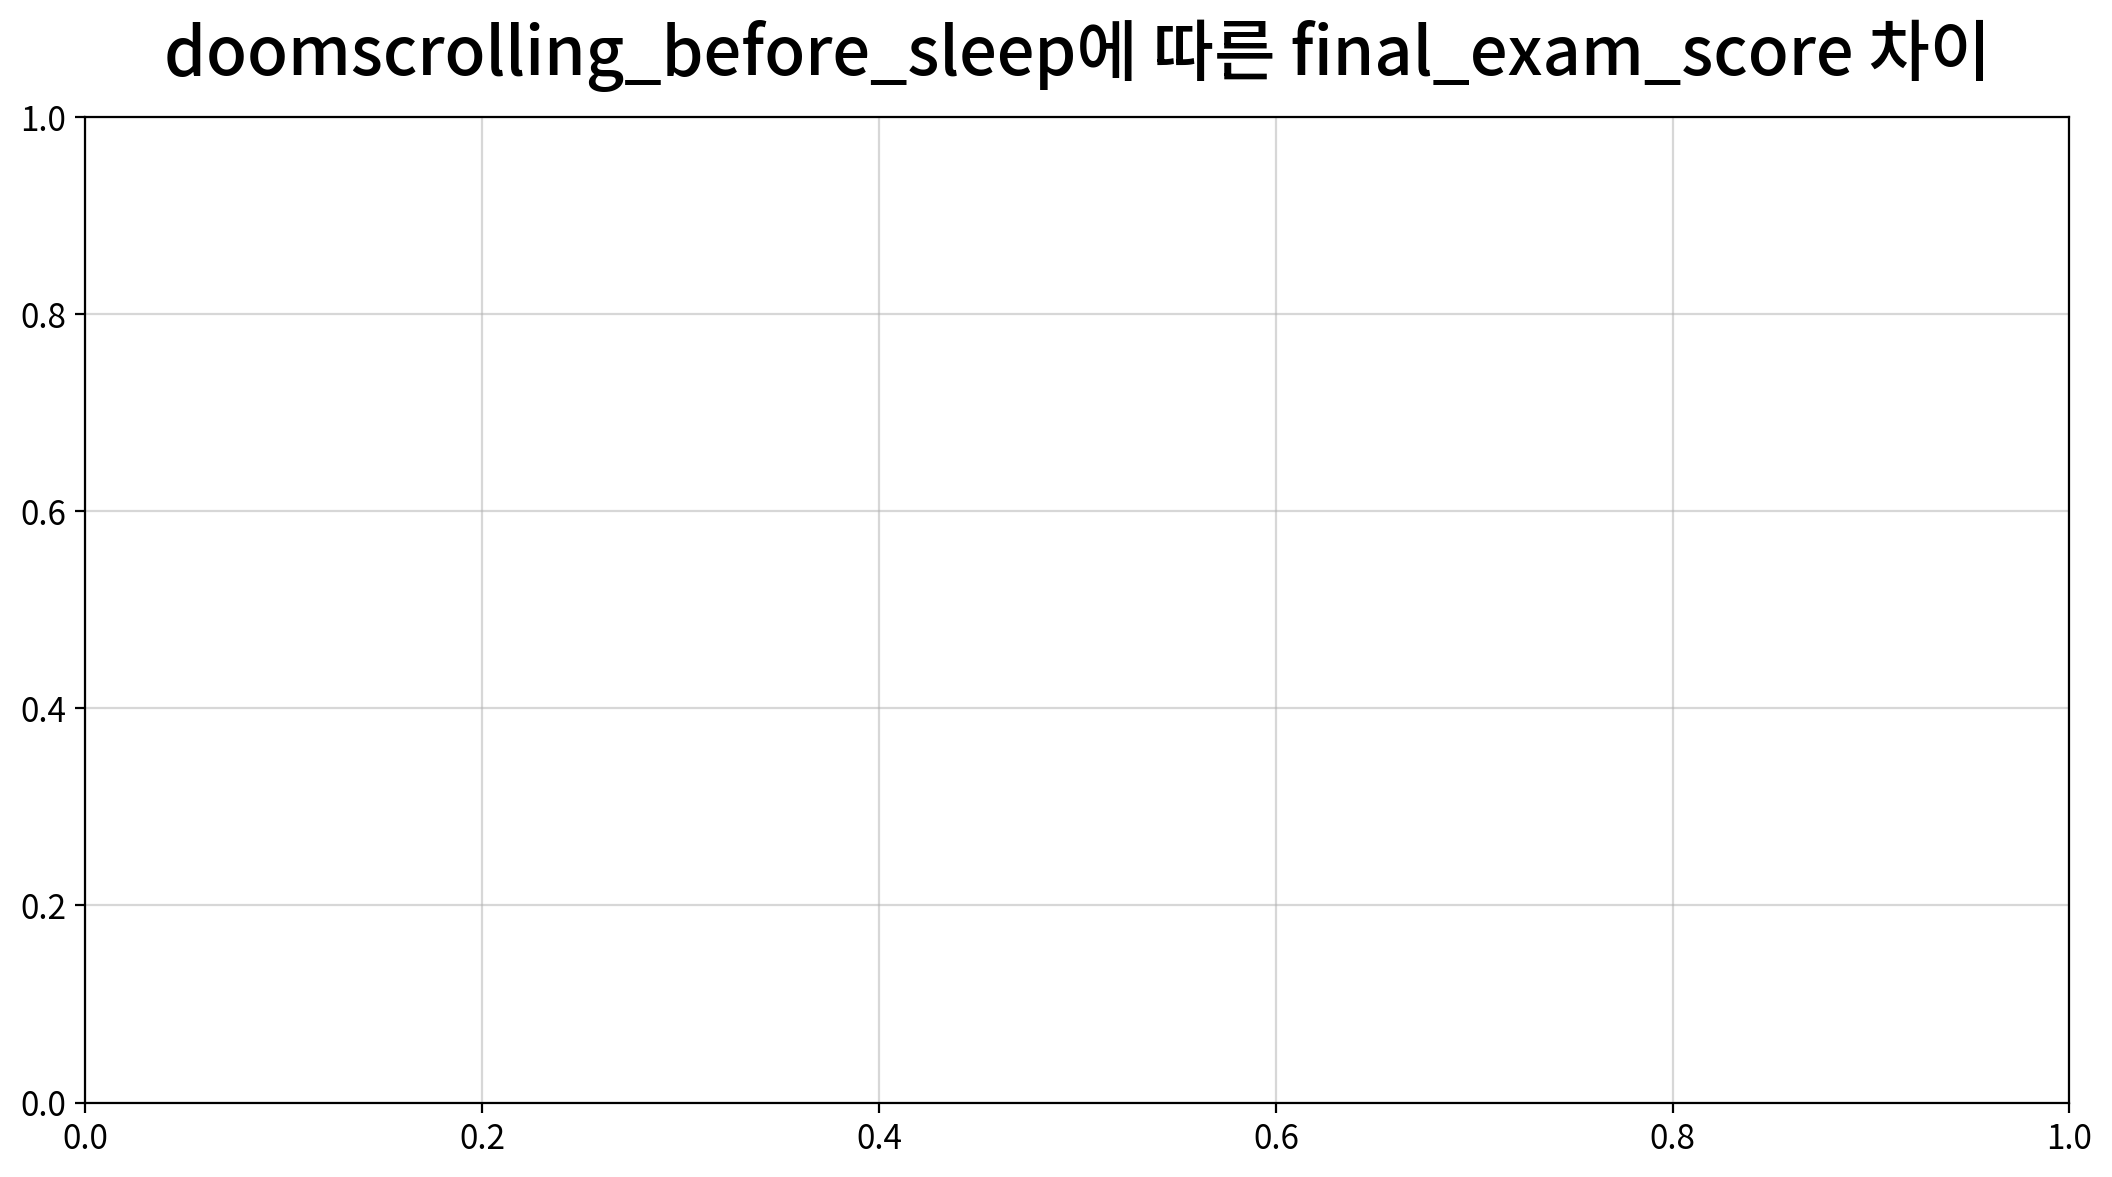

In [10]:
# doomscrolling_before_sleep
chas_medv = DataFrame({
    "예": df.loc[df["doomscrolling_before_sleep"] == 'Yes', target].reset_index(drop=True),
    "아니오" : df.loc[df["doomscrolling_before_sleep"] == 'No', target].reset_index(drop=True),
})

my_stats.test_independent(chas_medv, "예", "아니오", title="doomscrolling_before_sleep에 따른 final_exam_score 차이")

## #04. ANOVA

### 1. 일원분산분석

In [ ]:
# city_type
my_stats.anova_oneway(df, y="final_exam_score", between="city_type")

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,city_type,2,1997.218473,2.509159,0.081593,0.001719,Negligible


In [ ]:
# learning_style
my_stats.anova_oneway(df, y="final_exam_score", between="learning_style")

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,learning_style,3,1658.431687,0.66205,0.57541,0.000654,Negligible


In [ ]:
# career_goal
my_stats.anova_oneway(df, y="final_exam_score", between="career_goal")

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,career_goal,4,1494.32787,0.524625,0.717661,0.000717,Negligible


In [ ]:
# mental_state
my_stats.anova_oneway(df, y="final_exam_score", between="mental_state")

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,mental_state,3,1660.696077,102.145429,1.104856e-60,0.094779,Medium


### 3. 사후검정


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Balanced vs. Burnout: Custom statistical test, P_val:1.198e-12
Burnout vs. Distracted: Custom statistical test, P_val:0.000e+00
Distracted vs. Focused: Custom statistical test, P_val:9.293e-14
Balanced vs. Distracted: Custom statistical test, P_val:9.978e-01
Burnout vs. Focused: Custom statistical test, P_val:3.205e-13
Balanced vs. Focused: Custom statistical test, P_val:5.257e-13


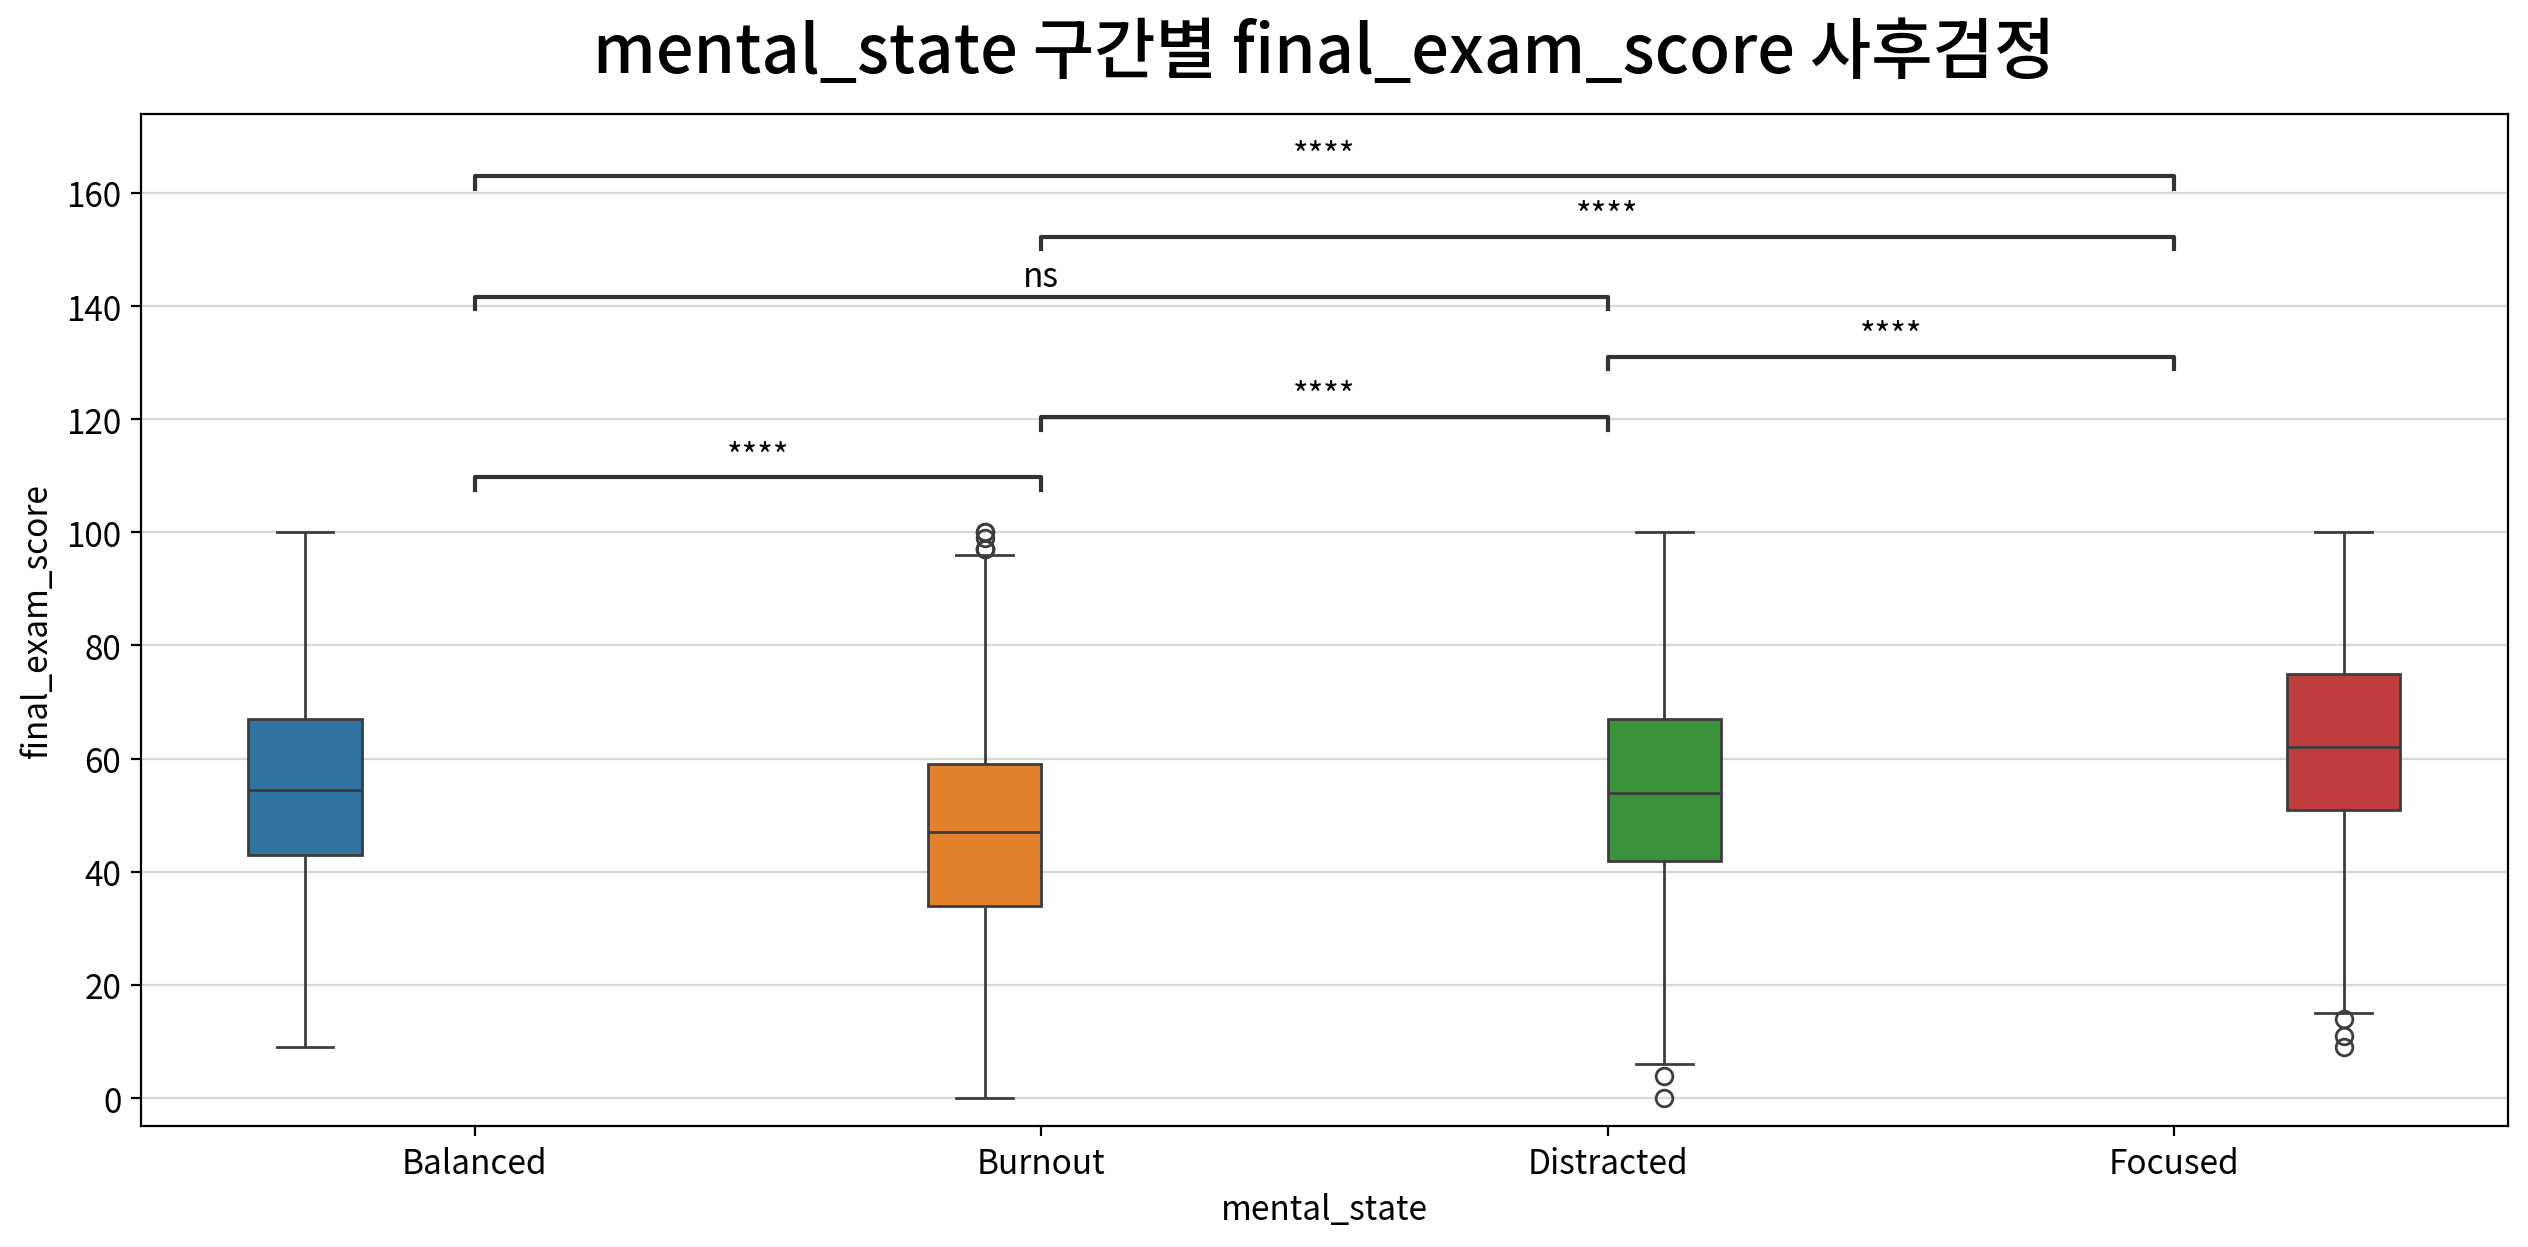

,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,Balanced,Burnout,54.807263,46.806623,8.000640,0.927636,8.624762,1468.151056,1.197931e-12,0.449332,True,Small
1,Games-Howell,Balanced,Distracted,54.807263,54.641772,0.165490,0.907215,0.182416,1491.318285,9.978458e-01,0.009405,False,Negligible
2,Games-Howell,Balanced,Focused,54.807263,63.110961,-8.303698,0.930047,-8.928255,1452.903387,5.256906e-13,-0.467772,True,Small
3,Games-Howell,Burnout,Distracted,46.806623,54.641772,-7.835150,0.908405,-8.625176,1535.875553,0.000000e+00,-0.438994,True,Small
4,Games-Howell,Burnout,Focused,46.806623,63.110961,-16.304338,0.931208,-17.508807,1491.623369,3.205214e-13,-0.905507,True,Large
5,Games-Howell,Distracted,Focused,54.641772,63.110961,-8.469189,0.910867,-9.297946,1516.299331,9.292567e-14,-0.475873,True,Small


In [ ]:
# mental_state
my_stats.posthoc_oneway(df, y="final_exam_score", between="mental_state",
                        title="mental_state 구간별 final_exam_score 사후검정")